# Formative 3, Part 1: Expectation-Maximization on Galton Heights

**Goal:** treat heights of two populations (mothers and sons) as one *unlabeled* pile and recover the two hidden Gaussians with EM written from scratch (NumPy only, no sklearn).

**Flow of this notebook:** data, the math, the code, the required tracking table, the fit, why a global mean split is the wrong tool, then the live posterior demo.

In [19]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- Settings you can change in one place ----
CSV_PATH     = "GaltonFamilies.csv"
PARENT       = "mother"             # "mother" or "father"
CHILD_GROUP  = "male"               # "male", "female" or None for all children
NAMES        = ("Child", "Parent")  # use ("Child", "Basketball Player") if the coach uses that wording
TEST_HEIGHT  = 66.0                 # the coach's number goes here
USE_INPUT    = False                # True means the notebook asks you to type the coach's height

# Fail early with a clear message if the dataset is missing
assert os.path.exists(CSV_PATH), f"Put {CSV_PATH} in the same folder as this notebook."

In [20]:
# EM implementation
def load_heights(csv_path, parent="mother", child_group="male"):
    """Return (pooled heights, parent heights, child heights).

    The pooled array is the ONLY thing the model sees: labels are never passed on.
    The separate parent and child arrays are kept just to evaluate the result.
    """
    df = pd.read_csv(csv_path)
    # Galton has one row per child, so a mother repeats once per child.
    # Keeping one row per family so each mother is counted exactly once.
    parents = df.drop_duplicates("family")[parent].to_numpy(float)
    # Restricting to one gender so the child group is a single bell curve, not two bumps.
    kids = df if child_group is None else df[df["gender"] == child_group]
    children = kids["childHeight"].to_numpy(float)
    return np.concatenate([parents, children]), parents, children


def gaussian_pdf(x, mu, var):
    """Normal density N(x | mu, var). Works on a single number or a whole array."""
    return np.exp(-((x - mu) ** 2) / (2 * var)) / np.sqrt(2 * np.pi * var)


def weighted_components(x, mu, var, pi):
    """pi_k * N(x | mu_k, var_k) for every component k.

    Returns an array of shape (len(x), K). The likelihood, the E-step and the
    classifier all need this same quantity, so it lives in one place (DRY).
    """
    return np.column_stack([pi[k] * gaussian_pdf(x, mu[k], var[k]) for k in range(len(mu))])


def log_likelihood(x, mu, var, pi):
    """l = sum_i log( sum_k pi_k N(x_i | mu_k, var_k) ). EM never makes this go down."""
    mixture_density = weighted_components(x, mu, var, pi).sum(axis=1)  # p(x_i) for each point
    return float(np.sum(np.log(mixture_density)))


def e_step(x, mu, var, pi):
    """Expectation step: responsibilities r_ik = P(component k | x_i), by Bayes' theorem."""
    w = weighted_components(x, mu, var, pi)       # numerator: prior * likelihood
    return w / w.sum(axis=1, keepdims=True)       # divide by the evidence so each row sums to 1


def m_step(x, r):
    """Maximization step: re-estimate parameters using responsibilities as weights."""
    nk = r.sum(axis=0)                                        # effective number of points per component
    mu = (r * x[:, None]).sum(axis=0) / nk                    # weighted mean
    var = (r * (x[:, None] - mu) ** 2).sum(axis=0) / nk       # weighted variance around the new mean
    pi = nk / len(x)                                          # mixing weight = share of total responsibility
    return mu, var, pi


def init_params(x, children_is_taller):
    """Data driven start: means at the 25th and 75th percentiles, pooled variance, equal weights.

    Component 1 is always the Child component, so if children are taller it gets the high mean.
    """
    lo, hi = np.percentile(x, [25, 75])
    mu = np.array([hi, lo]) if children_is_taller else np.array([lo, hi])
    var = np.array([x.var(), x.var()])
    pi = np.array([0.5, 0.5])
    return mu, var, pi


def fit_em(x, children_is_taller, tol=1e-6, max_iter=1000):
    """Run EM until the log-likelihood changes by less than tol.

    history rows: (iteration, mu1, mu2, var1, var2, pi1, pi2, log-likelihood).
    Iteration 0 is the initial state before any update.
    """
    mu, var, pi = init_params(x, children_is_taller)
    ll = log_likelihood(x, mu, var, pi)
    history = [(0, *mu, *var, *pi, ll)]
    for i in range(1, max_iter + 1):
        r = e_step(x, mu, var, pi)                  # E-step with the current parameters
        mu, var, pi = m_step(x, r)                  # M-step gives the new parameters
        new_ll = log_likelihood(x, mu, var, pi)
        history.append((i, *mu, *var, *pi, new_ll))
        if abs(new_ll - ll) < tol:                  # convergence: the fit has stopped improving
            break
        ll = new_ll
    return mu, var, pi, history


def tracking_table(history, rows=(0, 1, 2)):
    """The required table: initial state plus the first two iterations."""
    cols = ["Iteration", "mu1 (Children)", "mu2 (Parent)", "var1", "var2", "pi1", "pi2", "Log-Likelihood"]
    df = pd.DataFrame(history, columns=cols)
    return df[df["Iteration"].isin(rows)].round(4).reset_index(drop=True)


def classify(height, mu, var, pi, names=("Child", "Parent")):
    """Exact posterior P(group | height) for one height, by Bayes' theorem."""
    w = weighted_components(np.array([height], float), mu, var, pi)[0]
    return dict(zip(names, (w / w.sum()).tolist()))


## 1. Data

Each Galton row is one *child*, so a mother appears once per child. Counting her every time would repeat the same height up to 15 times and give the parent group far more weight than it deserves. We therefore keep **one row per family** for the parent.

We compare mothers with **sons** only. Pooling sons and daughters makes the child group itself bimodal (two bumps), which breaks the "one Gaussian per group" assumption and EM then splits the pooled data into tall and short people instead of children and parents.


n parents = 205, n children = 481, pooled n = 686
mean parents = 64.00, mean children = 69.23


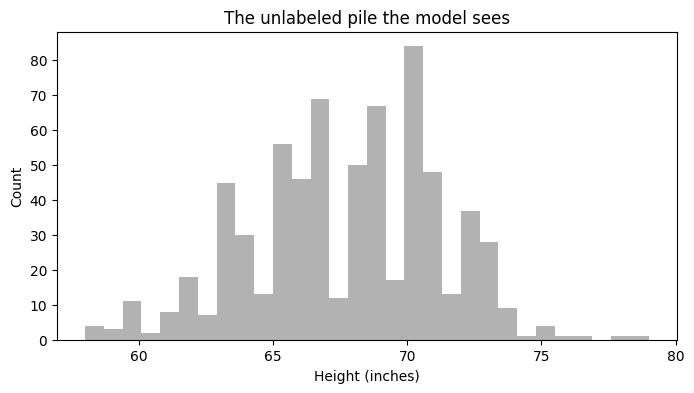

In [21]:
# Load the data. x is the unlabeled pile; parents and children are kept only for scoring later.
x, parents, children = load_heights(CSV_PATH, PARENT, CHILD_GROUP)

# Children are taller than parents in this setup, which decides which component we call "Child"
taller = children.mean() > parents.mean()
print(f"n parents = {len(parents)}, n children = {len(children)}, pooled n = {len(x)}")
print(f"mean parents = {parents.mean():.2f}, mean children = {children.mean():.2f}")

# Histogram of what the model actually sees: one pile, no labels
plt.figure(figsize=(8, 4))
plt.hist(x, bins=30, color="gray", alpha=0.6)
plt.xlabel("Height (inches)"); plt.ylabel("Count"); plt.title("The unlabeled pile the model sees")
plt.show()

## 2. The math

Model: each height comes from one of two Gaussians, chosen with mixing weights $\pi_1,\pi_2$ (they sum to 1).

$$p(x)=\sum_{k=1}^{2}\pi_k\,\mathcal N(x\mid\mu_k,\sigma_k^2)$$

**Initialization.** Means start at the 25th and 75th percentiles of the pooled data, both variances start at the pooled variance, and $\pi_1=\pi_2=0.5$. Starting from data driven values avoids the empty component problem that extreme starting points can cause.

**E-step (Bayes' theorem).** For every point, the responsibility of component $k$ is its posterior probability:

$$r_{ik}=\frac{\pi_k\,\mathcal N(x_i\mid\mu_k,\sigma_k^2)}{\sum_j \pi_j\,\mathcal N(x_i\mid\mu_j,\sigma_j^2)}$$

**M-step.** Re-estimate parameters using the responsibilities as weights, with $N_k=\sum_i r_{ik}$:

$$\mu_k=\frac{\sum_i r_{ik}x_i}{N_k},\qquad \sigma_k^2=\frac{\sum_i r_{ik}(x_i-\mu_k)^2}{N_k},\qquad \pi_k=\frac{N_k}{N}$$

**Log-likelihood and stopping.** After each update we compute

$$\ell=\sum_i\log\sum_k \pi_k\,\mathcal N(x_i\mid\mu_k,\sigma_k^2)$$

EM never decreases $\ell$. We stop when the change in $\ell$ is below $10^{-6}$, meaning another iteration would not change the fit.

## 3. Run EM and show the required tracking table (iterations 0, 1, 2)

In [22]:
# Fit the model on the pooled heights
mu, var, pi, hist = fit_em(x, children_is_taller=taller)

# Required tracking table: iteration 0 (initial state), 1 and 2
print(tracking_table(hist).to_string(index=False))
print(f"\nConverged after {hist[-1][0]} iterations")
print(f"Final: mu = {mu.round(3)}, var = {var.round(3)}, pi = {pi.round(3)}")

 Iteration  mu1 (Children)  mu2 (Parent)    var1    var2    pi1    pi2  Log-Likelihood
         0         70.2000       65.0000 12.1720 12.1720 0.5000 0.5000      -1861.4779
         1         69.5172       65.7391  7.6412  9.6136 0.5112 0.4888      -1825.3628
         2         69.5443       65.6961  7.1496  9.8663 0.5131 0.4869      -1824.6039

Converged after 414 iterations
Final: mu = [69.956 65.139], var = [5.395 7.488], pi = [0.526 0.474]


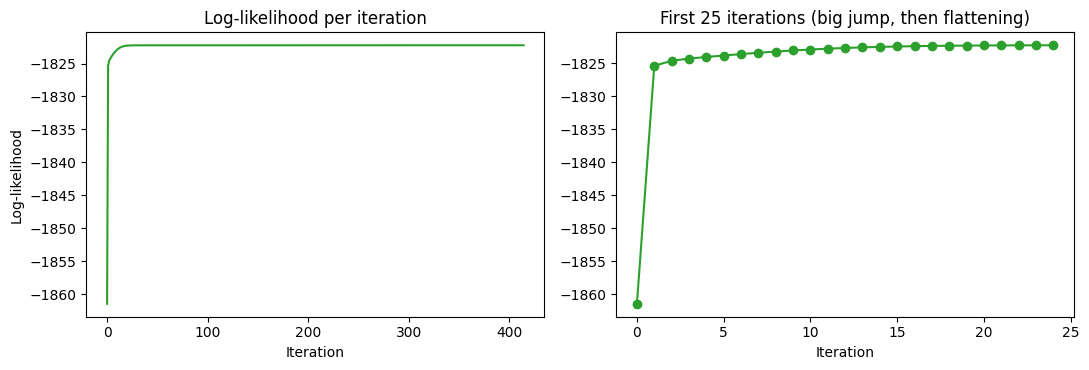

In [23]:
# Log-likelihood is the last column of every history row
ll_series = [h[-1] for h in hist]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(ll_series, color="tab:green")                  # whole run
ax[0].set_title("Log-likelihood per iteration")
ax[0].set_xlabel("Iteration"); ax[0].set_ylabel("Log-likelihood")
ax[1].plot(range(25), ll_series[:25], marker="o", color="tab:green")   # zoom on the first 25 steps
ax[1].set_title("First 25 iterations (big jump, then flattening)"); ax[1].set_xlabel("Iteration")
plt.tight_layout(); plt.show()

**How to read it.** Iteration 0 is the data driven start. The log-likelihood rises at every step and the curve flattens, which is exactly the convergence signal: once it changes by less than $10^{-6}$ the parameters have stopped moving.

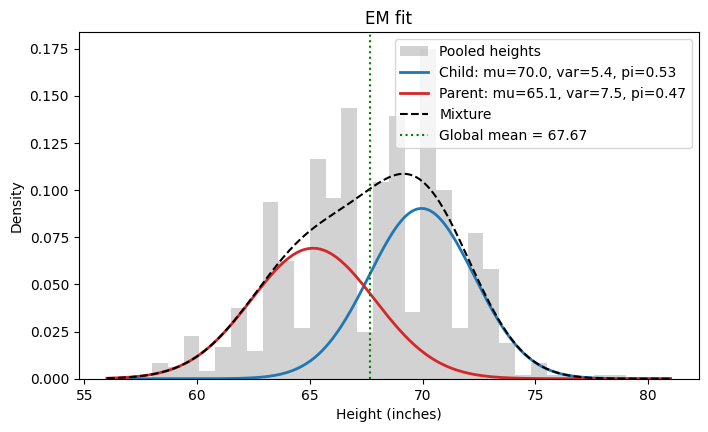

In [24]:
def plot_fit(x, mu, var, pi, names=NAMES):
    """Histogram of the pooled data with the two learned weighted Gaussians and their sum."""
    grid = np.linspace(x.min() - 2, x.max() + 2, 400)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.hist(x, bins=30, density=True, alpha=0.35, color="gray", label="Pooled heights")
    for k, c in zip(range(2), ("tab:blue", "tab:red")):
        # Each curve is pi_k * N(x | mu_k, var_k), so its area equals the mixing weight
        ax.plot(grid, pi[k] * gaussian_pdf(grid, mu[k], var[k]), color=c, lw=2,
                label=f"{names[k]}: mu={mu[k]:.1f}, var={var[k]:.1f}, pi={pi[k]:.2f}")
    ax.plot(grid, weighted_components(grid, mu, var, pi).sum(axis=1), "k--", label="Mixture")
    ax.axvline(x.mean(), color="green", ls=":", label=f"Global mean = {x.mean():.2f}")
    ax.set_xlabel("Height (inches)"); ax.set_ylabel("Density"); ax.set_title("EM fit"); ax.legend()
    plt.show()

plot_fit(x, mu, var, pi)

## 4. Should we just split at the global mean?

**No.** Cutting at the pooled mean and averaging each pile is a hard assignment, and it fails for three reasons:

1. **It ignores overlap.** Mothers and sons overlap between roughly 64 and 70 inches. A hard cut puts every point on one side with certainty, so a 67 inch person right next to the line is called a parent or a child with the same confidence as a 55 inch or 78 inch person.
2. **Its pile means are truncated estimates.** Each pile is a sliced piece of a bell curve (the lower pile has lost its upper tail, the upper pile its lower tail), so averaging a pile is biased in principle. EM fits all points with probability weights and no hard truncation. In practice the improvement depends on the data, so we print the numbers rather than assume them.
3. **It gives no uncertainty and learns nothing else.** EM also estimates the variances and the mixing proportions and reports a posterior probability per point (a soft assignment). A mean split can only say left or right.

The cell below measures this on our data instead of just claiming it.

In [25]:
# True labels are used ONLY here, to score the two methods. The model never saw them.
truth_child = np.concatenate([np.zeros(len(parents), bool), np.ones(len(children), bool)])

# Method A: hard split at the global mean. The taller side is called "child".
cut = x.mean()
pred_child_mean = (x > cut) if taller else (x <= cut)
acc_mean = np.mean(pred_child_mean == truth_child)
hi_pile, lo_pile = x[x > cut], x[x <= cut]          # the two piles and their means

# Method B: EM. Take the component with the larger responsibility (threshold 0.5), for scoring only.
r = e_step(x, mu, var, pi)
acc_em = np.mean((r[:, 0] > 0.5) == truth_child)

print(f"Global mean cut: {cut:.2f}")
print(f"Pile means from the cut: {hi_pile.mean():.2f} and {lo_pile.mean():.2f}")
print(f"True group means:        {children.mean():.2f} (children) and {parents.mean():.2f} (parents)")
print(f"EM learned means:        {mu[0]:.2f} and {mu[1]:.2f}\n")
print(f"Accuracy, global mean split: {acc_mean:.3f}")
print(f"Accuracy, EM (threshold 0.5): {acc_em:.3f}")

# How many points is EM unsure about? The hard split labels all of them with full certainty.
uncertain = np.sum(np.max(r, axis=1) < 0.8)
print(f"\n{uncertain} of {len(x)} points ({uncertain/len(x):.0%}) have EM confidence below 80%.")
print("A mean split would label all of them with full certainty.")

Global mean cut: 67.67
Pile means from the cut: 70.35 and 64.58
True group means:        69.23 (children) and 64.00 (parents)
EM learned means:        69.96 and 65.14

Accuracy, global mean split: 0.805
Accuracy, EM (threshold 0.5): 0.813

248 of 686 points (36%) have EM confidence below 80%.
A mean split would label all of them with full certainty.


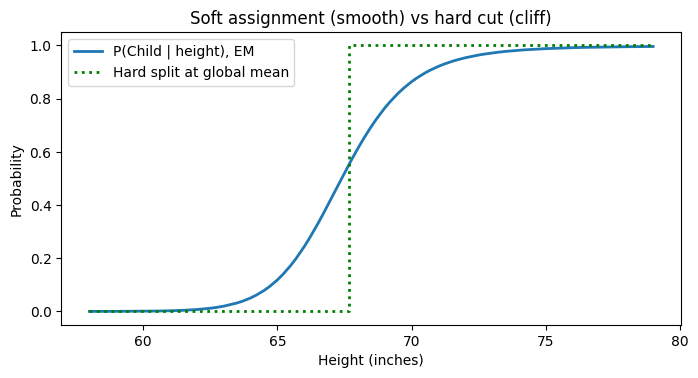

In [26]:
fig, ax = plt.subplots(figsize=(8, 3.8))
order = np.argsort(x)                                # sort so the curve is drawn left to right
ax.plot(x[order], r[order, 0], color="tab:blue", lw=2, label=f"P({NAMES[0]} | height), EM")
# The hard split is a cliff: probability jumps from 0 to 1 at the global mean
ax.step([x.min(), cut, x.max()], [0 if taller else 1, 1 if taller else 0, 1 if taller else 0],
        where="post", color="green", ls=":", lw=2, label="Hard split at global mean")
ax.set_xlabel("Height (inches)"); ax.set_ylabel("Probability"); ax.legend()
ax.set_title("Soft assignment (smooth) vs hard cut (cliff)")
plt.show()

**What the numbers say.** Forced into a yes or no decision, EM and the mean split score about the same, because two reasonably separated groups are already decently split by one threshold. EM's advantage is not a jump in accuracy. It returns a probability for every point (a large share of heights sit in the overlap and are genuinely uncertain), it estimates variances and mixing weights, and it needs no arbitrary cut. Also note honestly that neither method recovers the true group means perfectly, because the two groups overlap heavily.

## 5. Live classification: posterior probabilities for the coach's height

Bayes' theorem with the learned parameters:
$P(\text{Child}\mid h)=\dfrac{\pi_1\mathcal N(h\mid\mu_1,\sigma_1^2)}{\pi_1\mathcal N(h\mid\mu_1,\sigma_1^2)+\pi_2\mathcal N(h\mid\mu_2,\sigma_2^2)}$

Height = 66.0 inches
  P(Child) = 0.2434  (24.34%)
  P(Parent) = 0.7566  (75.66%)


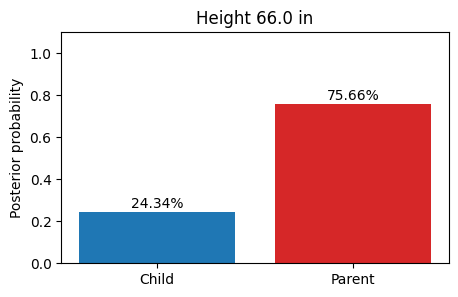

In [27]:
def show_posterior(height, mu, var, pi, names=NAMES):
    """Print and plot the exact posterior probabilities for one height."""
    post = classify(height, mu, var, pi, names)      # classify() comes from the EM cell above
    print(f"Height = {height} inches")
    for k, v in post.items():
        print(f"  P({k}) = {v:.4f}  ({v*100:.2f}%)")
    fig, ax = plt.subplots(figsize=(5, 3))
    bars = ax.bar(list(post), list(post.values()), color=["tab:blue", "tab:red"])
    ax.set_ylim(0, 1.1); ax.set_ylabel("Posterior probability"); ax.set_title(f"Height {height} in")
    for b in bars:                                   # write the percentage above each bar
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.02, f"{b.get_height():.2%}", ha="center")
    plt.show()
    return post

# Enter number: typed live for demo in presentation if USE_INPUT is True, otherwise TEST_HEIGHT from the settings cell
height = float(input("Coach's height (inches): ")) if USE_INPUT else TEST_HEIGHT
_ = show_posterior(height, mu, var, pi)

### Run it for a spread of heights

Showing a few values makes the soft assignment visible: short heights are clearly one group, tall heights the other, and heights near the overlap split the probability.

In [28]:
# A spread of heights shows the soft assignment: certain at the extremes, split in the overlap
rows = [{"Height": h, **{f"P({n})": round(p, 4) for n, p in classify(h, mu, var, pi).items()}}
        for h in (58, 62, 64, 66, 67, 68, 70, 72, 76)]
pd.DataFrame(rows)

,Height,P(Child),P(Parent)
0,58,0.0001,0.9999
1,62,0.0071,0.9929
2,64,0.0505,0.9495
3,66,0.2434,0.7566
4,67,0.4226,0.5774
5,68,0.6126,0.3874
6,70,0.8634,0.1366
7,72,0.9536,0.0464
8,76,0.9915,0.0085


## 6. Sanity checks (these should all pass)

In [29]:
ll_vals = np.array([h[-1] for h in hist])
assert np.all(np.diff(ll_vals) > -1e-9), "log-likelihood must never decrease"
assert abs(pi.sum() - 1) < 1e-9, "mixing weights must sum to 1"
assert np.allclose(e_step(x, mu, var, pi).sum(axis=1), 1), "responsibilities must sum to 1 per point"
assert abs(sum(classify(TEST_HEIGHT, mu, var, pi).values()) - 1) < 1e-9, "posteriors must sum to 1"
print("All checks passed.")

All checks passed.
